## Deep learning for predicting heart diseases.
This analysis uses the UCI heart disease data set

Janosi, A., Steinbrunn, W., Pfisterer, M., & Detrano, R. (1989). Heart Disease [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C52P4X.

In [44]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ['TF_USE_LEGACY_KERAS'] = '1'

import keras
from ucimlrepo import fetch_ucirepo 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle

from keras.utils import FeatureSpace
import tensorflow as tf

In [3]:
print(keras.__version__)

3.16.0.dev2026101004


In [4]:
print(keras.backend.backend())

tensorflow


### Load dataset

In [5]:
# fetch dataset 
heart_disease = fetch_ucirepo(id=45) 
  
# data (as pandas dataframes) 
X = heart_disease.data.features 
y = heart_disease.data.targets 
  
# variable information 
print(heart_disease.variables) 


        name     role         type demographic  \
0        age  Feature      Integer         Age   
1        sex  Feature  Categorical         Sex   
2         cp  Feature  Categorical         NaN   
3   trestbps  Feature      Integer         NaN   
4       chol  Feature      Integer         NaN   
5        fbs  Feature  Categorical         NaN   
6    restecg  Feature  Categorical         NaN   
7    thalach  Feature      Integer         NaN   
8      exang  Feature  Categorical         NaN   
9    oldpeak  Feature      Integer         NaN   
10     slope  Feature  Categorical         NaN   
11        ca  Feature      Integer         NaN   
12      thal  Feature  Categorical         NaN   
13       num   Target      Integer         NaN   

                                          description  units missing_values  
0                                                 NaN  years             no  
1                                                 NaN    NaN             no  
2              

In [6]:
print(X.columns) 
print(X.head())
print(y.head())

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal'],
      dtype='str')
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   1       145   233    1        2      150      0      2.3      3   
1   67    1   4       160   286    0        2      108      1      1.5      2   
2   67    1   4       120   229    0        2      129      1      2.6      2   
3   37    1   3       130   250    0        0      187      0      3.5      3   
4   41    0   2       130   204    0        2      172      0      1.4      1   

    ca  thal  
0  0.0   6.0  
1  3.0   3.0  
2  2.0   7.0  
3  0.0   3.0  
4  0.0   3.0  
   num
0    0
1    2
2    1
3    0
4    0


In [7]:
df = pd.concat([X, y], axis=1)
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


### Cleaning and tranforming dataset

In [8]:
df = df.rename(columns={"num": "target"})
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [9]:
df['target'].value_counts(dropna=False)

target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Based on previous analysis, 
- 0 means no heart disease (healthy)
- 1, 2, 3, 4 means presence of heart disease with varying degrees of severity.

This will be converted to a binary variable with 0 and 1 where 0 is healthy and 1 is presence of heart disease

In [10]:
df['target'] = (df['target'] > 0).astype(int)
df['target'].value_counts()

target
0    164
1    139
Name: count, dtype: int64

### Check for missing data

In [11]:
print(df.isna().value_counts())

age    sex    cp     trestbps  chol   fbs    restecg  thalach  exang  oldpeak  slope  ca     thal   target
False  False  False  False     False  False  False    False    False  False    False  False  False  False     297
                                                                                      True   False  False       4
                                                                                      False  True   False       2
Name: count, dtype: int64


In [12]:
print(f"for ca: {df['ca'].value_counts(dropna=False)}")
print(f"for thal: {df['thal'].value_counts(dropna=False)}")

for ca: ca
0.0    176
1.0     65
2.0     38
3.0     20
NaN      4
Name: count, dtype: int64
for thal: thal
3.0    166
7.0    117
6.0     18
NaN      2
Name: count, dtype: int64


In [13]:
df.dropna(how="any", inplace=True)
print(f"for ca: {df['ca'].value_counts(dropna=False)}")
print(f"for thal: {df['thal'].value_counts(dropna=False)}")
print(df.isna().value_counts())

for ca: ca
0.0    174
1.0     65
2.0     38
3.0     20
Name: count, dtype: int64
for thal: thal
3.0    164
7.0    115
6.0     18
Name: count, dtype: int64
age    sex    cp     trestbps  chol   fbs    restecg  thalach  exang  oldpeak  slope  ca     thal   target
False  False  False  False     False  False  False    False    False  False    False  False  False  False     297
Name: count, dtype: int64


In [14]:
print(df.dtypes)

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
target        int64
dtype: object


In [15]:
for col in ['ca', 'thal']:
    df[col] = df[col].astype(int)

In [45]:
with open("dataframe.pkl", "wb") as f:
    pickle.dump(df, f)

## Preprocessing
- Hot-one-encoding of categorical variables
- Normalizing numerical variables

Split the data into training and testing set before standardization to prevent data leakage.

Data leakage gives model an unfair advantage during training because it has seen the whole data before being splitted, 

resulting in over-optimistic performance scores 

that will fail when the model faces truly unseen real-world data.

In [16]:
#Set seed for reproducibility
SEED = 42

keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

Split into 80% training and 20% test

In [32]:
test_df = df.sample(frac=0.2, random_state=40)
train_df = df.drop(test_df.index)


#prep data for Keras
train_y = train_df['target']
train_X = train_df.drop(columns=['target'])

test_y = test_df['target']
test_X = test_df.drop(columns=['target'])

## The model

This is where the preprocessing happens, so that the model save the normalisation and preprocessing for predictions
- keras.layers.Normalization for Normalisation
- keras.layers.CategoryEncoding

In [18]:
categorical_variables = ['sex', 'cp', 'fbs', 'restecg','exang', 'ca', 'thal']
numerics = ['age', 'trestbps','chol', 'thalach', 'oldpeak', 'slope']

# Ensure categorical columns are integers and extract as NumPy arrays
for col in categorical_variables:
    train_X[col] = train_X[col].astype(int)

# Numerical data
train_num = train_X[numerics].to_numpy(dtype=np.float32)

num_input = keras.Input(
    shape=(len(numerics),),
    name="numerical_input"
)

normalizer = keras.layers.Normalization()
normalizer.adapt(train_num)

normalized_num = normalizer(num_input)

# Categorical data
cat_inputs = []
encoded_categories = []

for col in categorical_variables:
    # One input per categorical variable
    inp = keras.Input(shape=(1,), dtype="int32", name=col)
    cat_inputs.append(inp)

    # Learn this variable's vocabulary independently
    lookup = keras.layers.IntegerLookup(
        output_mode="one_hot",
        num_oov_indices=1,
        name=f"{col}_lookup"
    )

    lookup.adapt(train_X[col].to_numpy(dtype=np.int32))

    encoded = lookup(inp)
    encoded_categories.append(encoded)
    
# Combine categorical features
encoded_cat = keras.layers.concatenate(encoded_categories)
combined = keras.layers.concatenate(
    [normalized_num, encoded_cat]
)

In [35]:
h = keras.layers.Dense(6, activation="relu", name="Hidden")(combined)
output = keras.layers.Dense(1, activation="sigmoid", name="Output")(h)

model = keras.Model(
    inputs=[num_input] + cat_inputs,
    outputs=output
)

#optimization parameters
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ sex (InputLayer)    │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cp (InputLayer)     │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fbs (InputLayer)    │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ restecg             │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ exang (InputLayer)  │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ca (InputLayer)     │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ thal (InputLayer)   │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ numerical_input     │ (None, 6)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sex_lookup          │ (None, 3)         │          0 │ sex[0][0]         │
│ (IntegerLookup)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cp_lookup           │ (None, 5)         │          0 │ cp[0][0]          │
│ (IntegerLookup)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fbs_lookup          │ (None, 3)         │          0 │ fbs[0][0]         │
│ (IntegerLookup)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ restecg_lookup      │ (None, 4)         │          0 │ restecg[0][0]     │
│ (IntegerLookup)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ exang_lookup        │ (None, 3)         │          0 │ exang[0][0]       │
│ (IntegerLookup)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ca_lookup           │ (None, 5)         │          0 │ ca[0][0]          │
│ (IntegerLookup)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ thal_lookup         │ (None, 4)         │          0 │ thal[0][0]        │
│ (IntegerLookup)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 6)         │         13 │ numerical_input[… │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 27)        │          0 │ sex_lookup[0][0], │
│ (Concatenate)       │                   │            │ cp_lookup[0][0],  │
│                     │                   │            │ fbs_lookup[0][0], │
│                     │                   │            │ restecg_lookup[0… │
│                     │                   │            │ exang_lookup[0][… │
│                     │                   │            │ ca_lookup[0][0],  │
│                     │                   │            │ thal_lookup[0][0

 Total params: 224 (900.00 B)

 Trainable params: 211 (844.00 B)

 Non-trainable params: 13 (56.00 B)

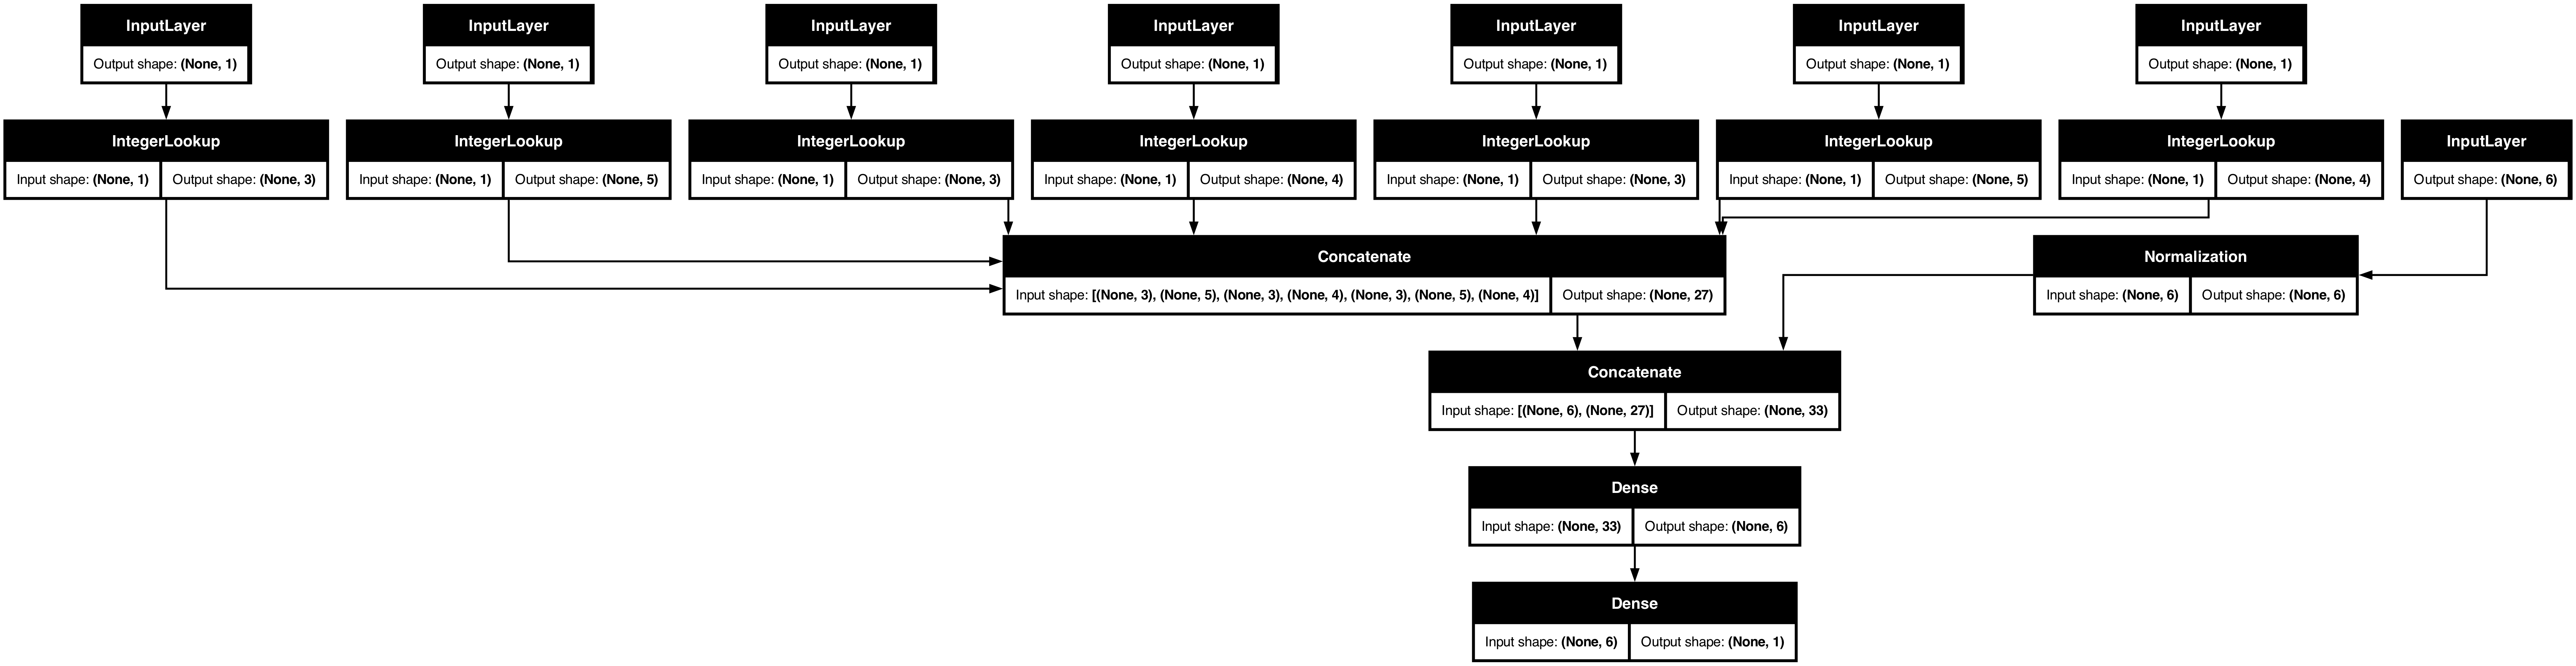

In [36]:
keras.utils.plot_model(model, show_shapes=True)

In [37]:
train_inputs = [
    train_num,
    *[
        train_X[col].to_numpy(dtype=np.int32).reshape(-1, 1)
        for col in categorical_variables
    ]
]

history = model.fit(
    train_inputs,
    train_y,
    batch_size=32,
    epochs=300,
    validation_split=0.2
)

Epoch 1/300


E0000 00:00:1791728395.490242 41606469 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_22}}


6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.4263 - loss: 0.7658 WARNING:tensorflow:5 out of the last 347 calls to <function TensorFlowTrainer._make_function.<locals>.one_step_on_data at 0x1443a1010> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/step - accuracy: 0.4263 - loss: 0.7658 - val_accuracy: 0.5833 - val_loss: 0.6988
Epoch 2/300
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4263 - loss: 0.7529 - val_accuracy: 0.5625 - val_

In [38]:
history_dict = history.history
history_dict.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

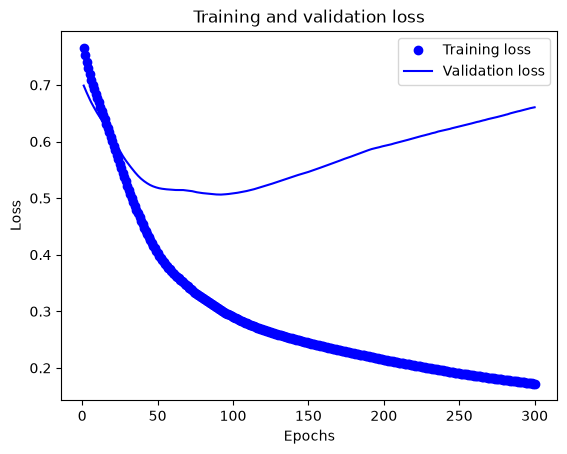

In [39]:
loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]
epochs = range(1, len(loss_values) + 1)
plt.plot(epochs, loss_values, "bo", label="Training loss")
plt.plot(epochs, val_loss_values, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

This is a clear case of **overfitting**

At 50 epoch the Training error was reducing but the validiation error was increasing which indicate that the model is not generalising well on unseen data

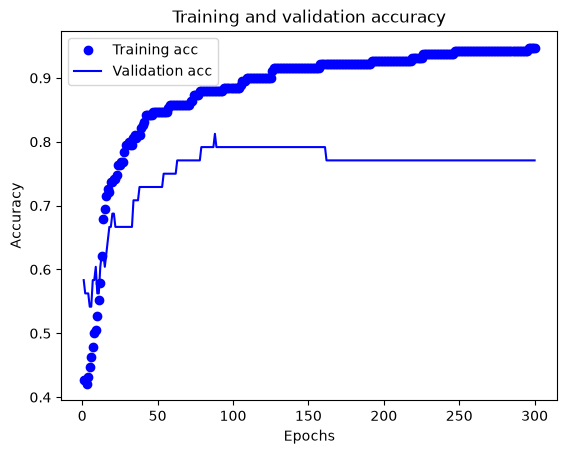

In [40]:
plt.clf()
acc = history_dict["accuracy"]
val_acc = history_dict["val_accuracy"]
plt.plot(epochs, acc, "bo", label="Training acc")
plt.plot(epochs, val_acc, "b", label="Validation acc")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [41]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=30,
    restore_best_weights=True
)

history = model.fit(
    train_inputs,
    train_y,
    batch_size=32,
    epochs=50,
    validation_split=0.2,
    callbacks=[early_stopping]
)

Epoch 1/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9474 - loss: 0.1718 - val_accuracy: 0.7708 - val_loss: 0.6613
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9474 - loss: 0.1715 - val_accuracy: 0.7708 - val_loss: 0.6620
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9474 - loss: 0.1711 - val_accuracy: 0.7708 - val_loss: 0.6626
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9474 - loss: 0.1708 - val_accuracy: 0.7708 - val_loss: 0.6633
Epoch 5/50


E0000 00:00:1791728429.281234 41606469 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_22}}


6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9474 - loss: 0.1705 - val_accuracy: 0.7708 - val_loss: 0.6641
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9474 - loss: 0.1702 - val_accuracy: 0.7500 - val_loss: 0.6648
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9474 - loss: 0.1699 - val_accuracy: 0.7500 - val_loss: 0.6652
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9474 - loss: 0.1696 - val_accuracy: 0.7500 - val_loss: 0.6660
Epoch 9/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9474 - loss: 0.1692 - val_accuracy: 0.7500 - val_loss: 0.6668
Epoch 10/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9474 - loss: 0.1689 - val_accuracy: 0.7500 - val_loss: 0.6676
Epoch 11/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9474 - loss: 0.1686 - val_accuracy: 0.7500 - val_loss: 0.6682
Epoch 12/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9474 - loss: 0.1683 - val_accuracy: 0.7500 - val_loss: 0.6687
Epoch 13/50
6/6

In [42]:
test_num = test_X[numerics].to_numpy(dtype=np.float32)

test_inputs = [
    test_num,
    *[
        test_X[col].to_numpy(dtype=np.int32).reshape(-1, 1)
        for col in categorical_variables
    ]
]

test_loss, test_accuracy = model.evaluate(test_inputs, test_y)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8475 - loss: 0.3998
Test loss: 0.3998126685619354
Test accuracy: 0.8474576473236084


In [43]:
print("Final training accuracy:",
      history.history["accuracy"][-1])

print("Final validation accuracy:",
      history.history["val_accuracy"][-1])

print("Test accuracy:", test_accuracy)

Final training accuracy: 0.9526315927505493
Final validation accuracy: 0.75
Test accuracy: 0.8474576473236084
